In [40]:
import uproot
import numpy as np

def get_daily_count_for_detector(
    detector,
    base_path="dayabay_full_dataset_root_1-0-0/root/dayabay_dataset/"
):
    root_file = f"{base_path}dayabay_events_{detector}.root"

    with uproot.open(root_file) as f:
        days = f["events"]["day"].array(library="np")

    counts = np.bincount(days.astype(np.int64))

    return {day: int(count) for day, count in enumerate(counts)}

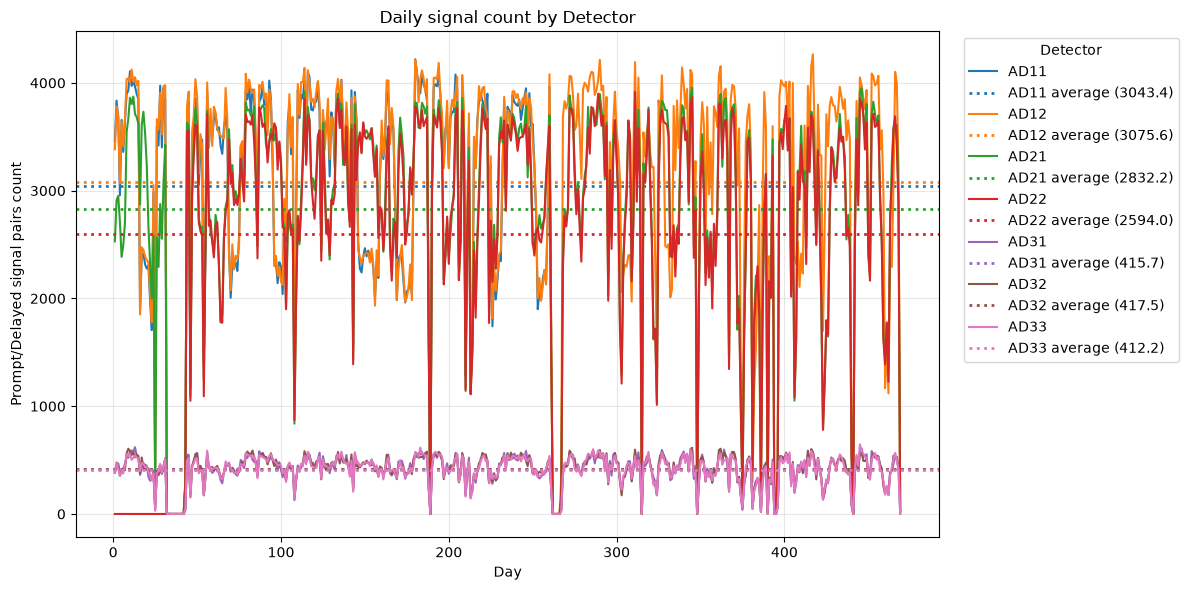

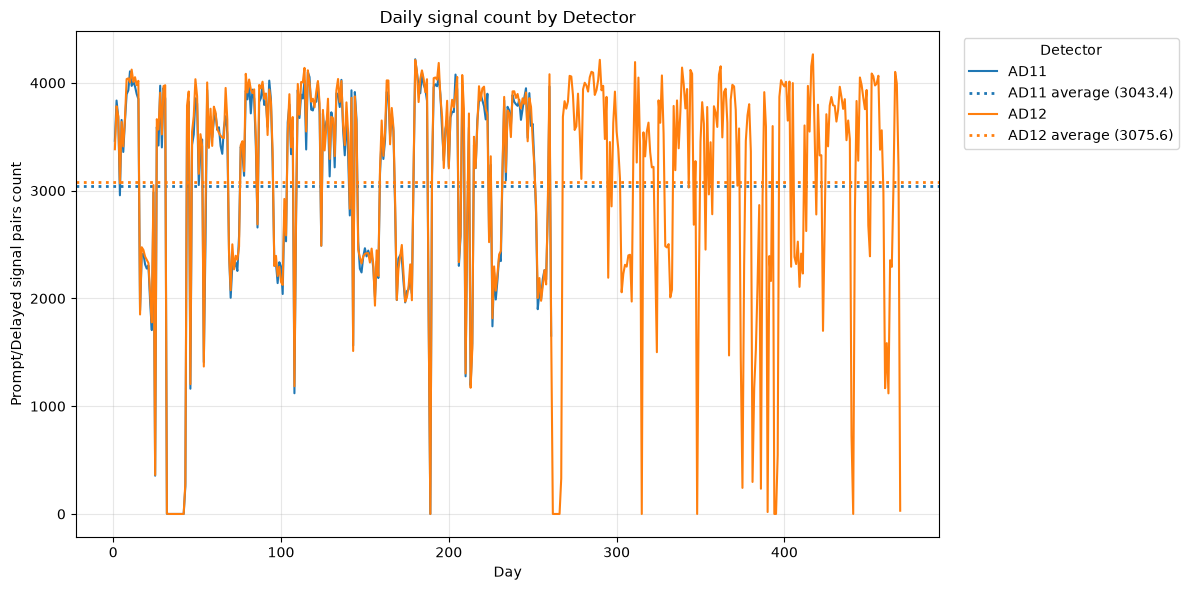

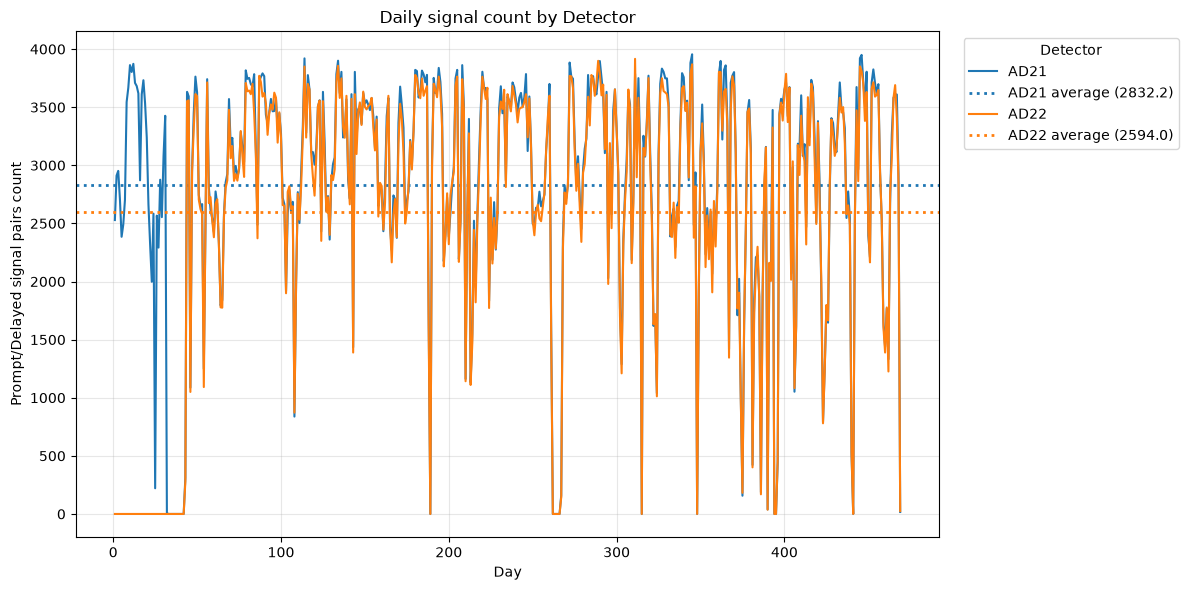

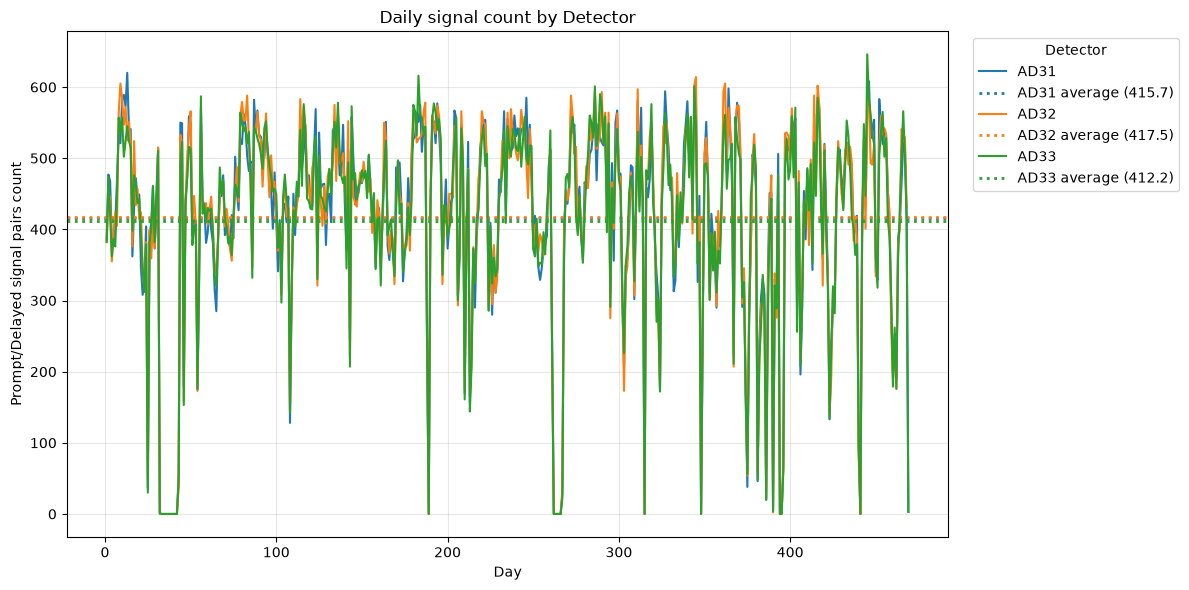

In [69]:
import matplotlib.pyplot as plt

list_of_list_of_detectors = [
    ["AD11", "AD12", "AD21", "AD22", "AD31", "AD32", "AD33"],
    ["AD11", "AD12"],
    ["AD21", "AD22"],
    ["AD31", "AD32", "AD33"]
]

for detectors in list_of_list_of_detectors:
    fig, ax = plt.subplots(figsize=(12, 6))

    for detector in detectors:
        daily_count = get_daily_count_for_detector(detector)

        days = sorted(daily_count.keys())
        counts = [daily_count[day] for day in days]


        # Create a complete daily array, including days with zero events
        max_day = max(daily_count)
        daily_counts = np.array([
            daily_count.get(day, 0)
            for day in range(max_day + 1)
        ])

        # Sum counts over consecutive 7-day periods
        weekly_counts = np.array([
            daily_counts[i:i + 7].sum()
            for i in range(0, len(daily_counts), 7)
        ])

        weeks = np.arange(1, len(weekly_counts) + 1)

        # Plot weekly counts
        line, = ax.plot(
            weeks,
            weekly_counts,
            label=detector,
            linewidth=1.5
        )

        color = line.get_color()

        # Plot average weekly count as a dotted line
        average = weekly_counts.mean()

        ax.axhline(
            y=average,
            color=color,
            linestyle=":",
            linewidth=2,
            label=f"{detector} average ({average:.1f})"
        )



    ax.set_xlabel("Day")
    ax.set_ylabel("Prompt/Delayed signal pairs count")
    ax.set_title("Daily signal count by Detector")
    ax.grid(True, alpha=0.3)

    ax.legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.savefig('+'.join(detectors) + ".pdf")
    plt.show()

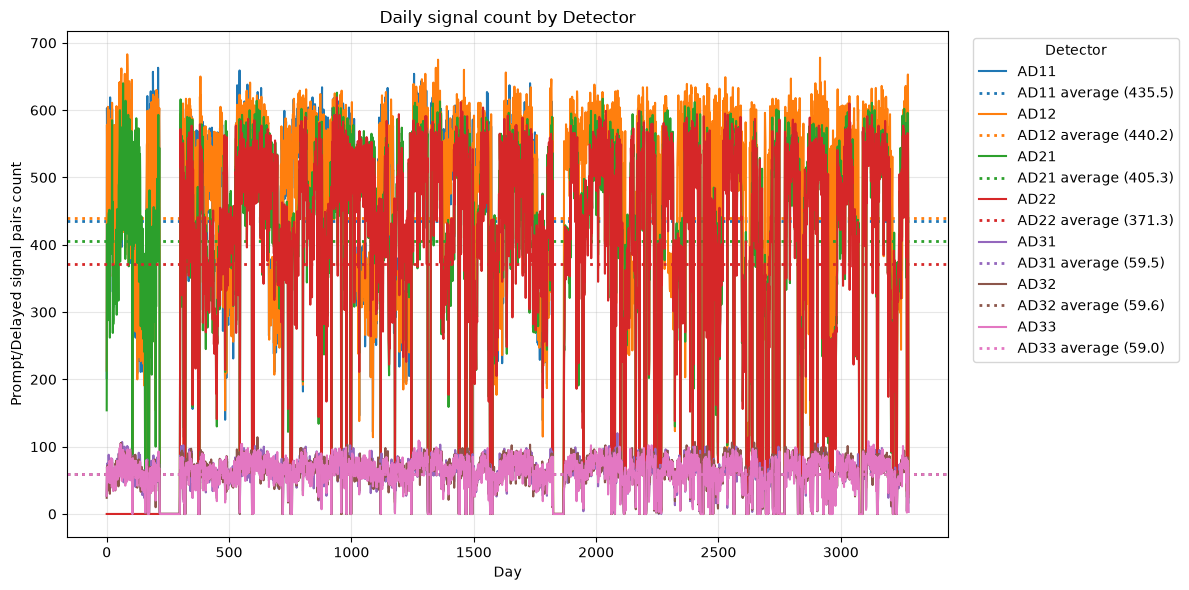

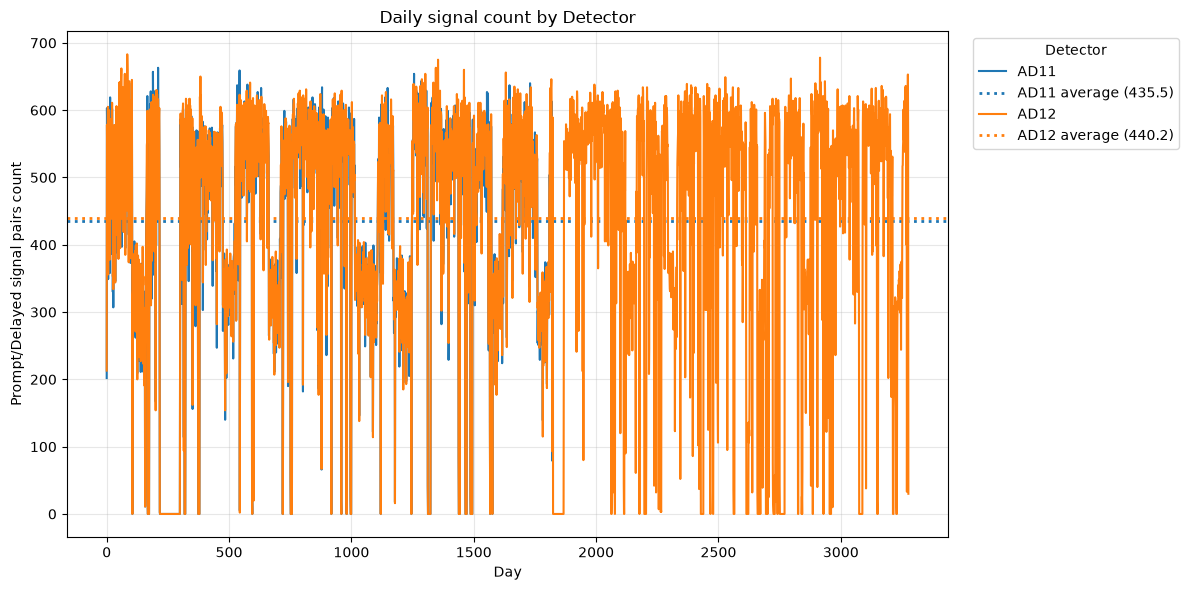

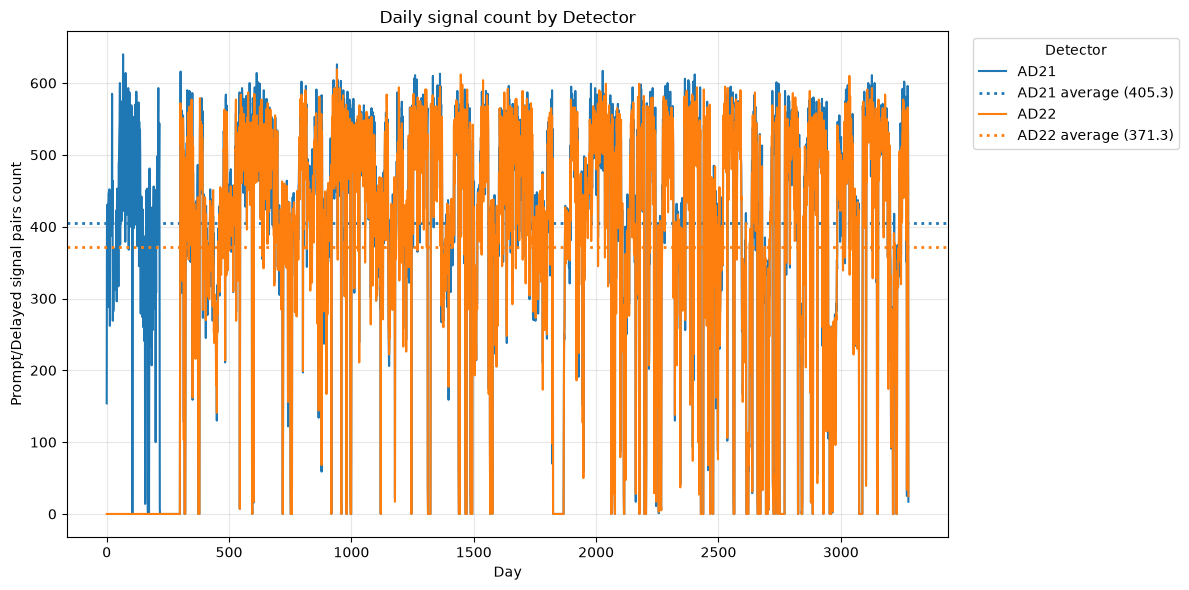

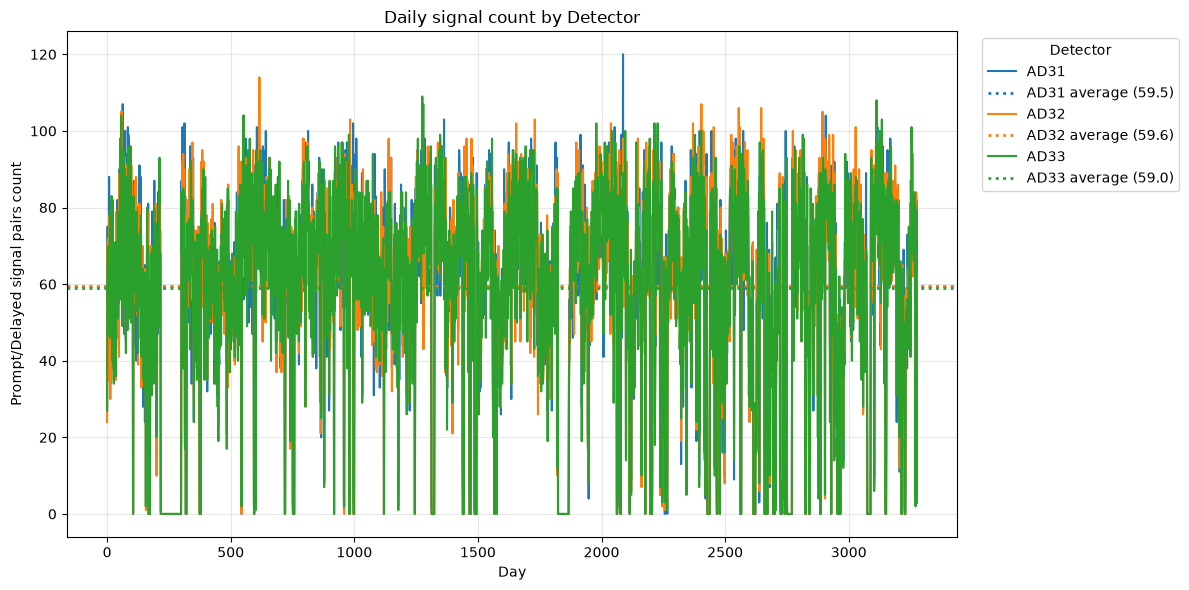

In [70]:
import matplotlib.pyplot as plt

list_of_list_of_detectors = [
    ["AD11", "AD12", "AD21", "AD22", "AD31", "AD32", "AD33"],
    ["AD11", "AD12"],
    ["AD21", "AD22"],
    ["AD31", "AD32", "AD33"]
]

for detectors in list_of_list_of_detectors:
    fig, ax = plt.subplots(figsize=(12, 6))

    for detector in detectors:
        daily_count = get_daily_count_for_detector(detector)

        days = sorted(daily_count.keys())
        counts = [daily_count[day] for day in days]

        # Plot daily counts
        line, = ax.plot(days, counts, label=detector, linewidth=1.5)
        color = line.get_color()

        # Calculate and plot the average daily count
        average = sum(counts) / len(counts) if counts else 0
        ax.axhline(
            y=average,
            color=color,
            linestyle=":",
            linewidth=2,
            label=f"{detector} average ({average:.1f})"
        )

    ax.set_xlabel("Day")
    ax.set_ylabel("Prompt/Delayed signal pairs count")
    ax.set_title("Daily signal count by Detector")
    ax.grid(True, alpha=0.3)

    ax.legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.savefig('+'.join(detectors) + ".pdf")
    plt.show()